# AgroLens — Radish Disease Classifier Training Notebook

Trains a MobileNetV2-based leaf disease classifier on a radish leaf dataset, evaluates it,
saves it, and includes a real-time image-upload inference tester.

**Important note before you run this:** radish is not part of the standard PlantVillage
dataset, so this notebook doesn't assume the `color/grayscale/segmented` folder layout
from before. Section 2 below auto-detects your dataset's actual folder structure instead.
If auto-detection fails, print your folder's contents (`os.listdir(DATASET_DIR)`) and tell
me what it looks like so I can adjust the loading logic to match exactly.

**How to use this notebook:**
1. Set `DATASET_DIR` in the Configuration cell to wherever you unzipped the radish dataset.
2. Run all cells top to bottom (`Kernel > Restart & Run All`).
3. Use the last section to upload any leaf photo and see a live prediction.

This notebook trains on your **laptop/Colab GPU**, not on the ESP32-CAM. The ESP32-CAM only
runs the final quantized model (a later conversion step, not covered here).


## 0. Install & import dependencies

In [ ]:
# Run this once. Restart the kernel if TensorFlow was just installed.
# !pip install tensorflow scikit-learn matplotlib seaborn pillow ipywidgets --quiet


In [1]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: []


## 1. Configuration — EDIT THIS CELL

Set `DATASET_DIR` to the folder where you unzipped the radish dataset.

`FILTER_KEYWORD` is left as `None` since this is already a radish-only dataset — no need
to filter by crop name like the tomato notebook did. Leave it `None` unless you specifically
want to keep only some of the classes inside this dataset (e.g. only certain disease types).


In [2]:
# ============================================================
# EDIT THESE VALUES
# ============================================================

DATASET_DIR = r"C:\Major\Image Dataset for Radish Plant Leaf Disease Detection and Freshness Assessment from Bangladesh"   # <-- CHANGE THIS. Use an r"..." raw string
                                                        # on Windows so backslashes aren't misread.

FILTER_KEYWORD = None        # set to a substring (e.g. "leaf") to keep only matching class folders.
                              # Leave as None to use every class folder found.

IMG_SIZE = (96, 96)          # 96x96 keeps the model small enough for later TFLite Micro conversion.
                              # Use 160x160 or 224x224 only if you plan to prune/quantize aggressively.

BATCH_SIZE = 32
EPOCHS = 15
SEED = 42

WORK_DIR = "./agrolens_radish_work"      # scratch folder this notebook creates
FILTERED_DIR = os.path.join(WORK_DIR, "filtered_dataset")
SPLIT_DIR = os.path.join(WORK_DIR, "split_dataset")
MODEL_SAVE_PATH = os.path.join(WORK_DIR, "agrolens_radish_model.keras")
MODEL_SAVEDMODEL_PATH = os.path.join(WORK_DIR, "agrolens_radish_savedmodel")

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.makedirs(WORK_DIR, exist_ok=True)
assert os.path.isdir(DATASET_DIR), f"DATASET_DIR does not exist: {DATASET_DIR}. Fix the path above."
print("Config set. Dataset dir:", DATASET_DIR)


Config set. Dataset dir: C:\Major\Image Dataset for Radish Plant Leaf Disease Detection and Freshness Assessment from Bangladesh


## 2. Auto-detect dataset structure

Different Kaggle radish datasets are packaged differently. This cell checks for the common
layouts, in order:

1. **Already split**: `DATASET_DIR/train/<class>/`, `DATASET_DIR/val or valid/<class>/`, `DATASET_DIR/test/<class>/`
2. **Flat class folders**: `DATASET_DIR/<class>/*.jpg` directly (most common — same as the tomato notebook)
3. **One extra nesting level**: `DATASET_DIR/<some_folder>/<class>/*.jpg`

It prints what it found. If none of these match your download, run
`print(os.listdir(DATASET_DIR))` yourself, share the output, and the loading logic can be
adjusted to match.


In [3]:
def looks_like_class_folder(path):
    """A folder 'looks like' a class folder if it directly contains image files."""
    if not os.path.isdir(path):
        return False
    exts = (".jpg", ".jpeg", ".png", ".bmp")
    for f in os.listdir(path)[:20]:
        if f.lower().endswith(exts):
            return True
    return False

top_level = [d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))]
top_level_lower = [d.lower() for d in top_level]

DATASET_MODE = None
PRESPLIT_DIRS = {}

# Case 1: already split into train/val/test
train_candidates = [d for d in top_level if d.lower() in ("train", "training")]
val_candidates = [d for d in top_level if d.lower() in ("val", "valid", "validation")]
test_candidates = [d for d in top_level if d.lower() in ("test", "testing")]

if train_candidates and (val_candidates or test_candidates):
    DATASET_MODE = "presplit"
    PRESPLIT_DIRS["train"] = os.path.join(DATASET_DIR, train_candidates[0])
    PRESPLIT_DIRS["val"] = os.path.join(DATASET_DIR, val_candidates[0]) if val_candidates else None
    PRESPLIT_DIRS["test"] = os.path.join(DATASET_DIR, test_candidates[0]) if test_candidates else None
    print("Detected an already train/val/test split dataset:")
    print(PRESPLIT_DIRS)

# Case 2: flat class folders directly under DATASET_DIR
elif any(looks_like_class_folder(os.path.join(DATASET_DIR, d)) for d in top_level):
    DATASET_MODE = "flat"
    SOURCE_DIR = DATASET_DIR
    print("Detected flat class-folder layout directly under DATASET_DIR.")
    print("Classes found:", top_level)

# Case 3: one extra nesting level (e.g. DATASET_DIR/RadishDataset/<class>/)
else:
    nested_found = False
    for d in top_level:
        inner = os.path.join(DATASET_DIR, d)
        inner_subdirs = [x for x in os.listdir(inner) if os.path.isdir(os.path.join(inner, x))]
        if inner_subdirs and any(looks_like_class_folder(os.path.join(inner, x)) for x in inner_subdirs):
            DATASET_MODE = "nested"
            SOURCE_DIR = inner
            nested_found = True
            print(f"Detected class folders nested one level deeper, inside: {inner}")
            print("Classes found:", inner_subdirs)
            break
    if not nested_found:
        print("Could not auto-detect the structure.")
        print("Top-level contents of DATASET_DIR:", top_level)
        raise RuntimeError(
            "Auto-detection failed. Print os.listdir(DATASET_DIR) and share the output "
            "so the loading logic can be adjusted to match your dataset's actual layout."
        )

print("\nDataset mode:", DATASET_MODE)


Detected flat class-folder layout directly under DATASET_DIR.
Classes found: ['Radish Black leaf spot', 'Radish Downey mildew', 'Radish flea beetle', 'Radish Fresh leaf', 'Radish Mosaic virus']

Dataset mode: flat


## 3. Build the working train/val/test split

If your dataset was already split (Case 1 above), this just filters classes if requested
and copies it into a consistent working folder. If it was a flat or nested layout (Cases 2/3),
this performs a fresh stratified 70/15/15 split.


In [4]:
def clean_dataset(root_dir):
    from PIL import Image
    removed = 0
    for subdir, _, files in os.walk(root_dir):
        for f in files:
            path = os.path.join(subdir, f)
            try:
                img = Image.open(path)
                img.verify()
            except Exception:
                os.remove(path)
                removed += 1
    return removed


def filter_classes(source_dir, dest_dir, keyword):
    all_classes = sorted([d for d in os.listdir(source_dir) if os.path.isdir(os.path.join(source_dir, d))])
    if keyword:
        selected = [c for c in all_classes if keyword.lower() in c.lower()]
    else:
        selected = all_classes
    assert len(selected) > 0, "No classes matched FILTER_KEYWORD. Check spelling or set it to None."

    if os.path.exists(dest_dir):
        shutil.rmtree(dest_dir)
    os.makedirs(dest_dir, exist_ok=True)
    for c in selected:
        shutil.copytree(os.path.join(source_dir, c), os.path.join(dest_dir, c))
    return selected


def split_dataset(source_dir, dest_dir, split_ratio=(0.7, 0.15, 0.15), seed=SEED):
    assert abs(sum(split_ratio) - 1.0) < 1e-6
    if os.path.exists(dest_dir):
        shutil.rmtree(dest_dir)

    classes = sorted([d for d in os.listdir(source_dir) if os.path.isdir(os.path.join(source_dir, d))])
    rng = random.Random(seed)

    for split_name in ["train", "val", "test"]:
        for c in classes:
            os.makedirs(os.path.join(dest_dir, split_name, c), exist_ok=True)

    for c in classes:
        files = os.listdir(os.path.join(source_dir, c))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * split_ratio[0])
        n_val = int(n * split_ratio[1])

        for f in files[:n_train]:
            shutil.copy(os.path.join(source_dir, c, f), os.path.join(dest_dir, "train", c, f))
        for f in files[n_train:n_train + n_val]:
            shutil.copy(os.path.join(source_dir, c, f), os.path.join(dest_dir, "val", c, f))
        for f in files[n_train + n_val:]:
            shutil.copy(os.path.join(source_dir, c, f), os.path.join(dest_dir, "test", c, f))

    return classes


if DATASET_MODE == "presplit":
    # Copy (optionally filtered) presplit folders into a consistent SPLIT_DIR/train,val,test layout
    if os.path.exists(SPLIT_DIR):
        shutil.rmtree(SPLIT_DIR)
    os.makedirs(SPLIT_DIR, exist_ok=True)

    for split_name, src in PRESPLIT_DIRS.items():
        if src is None:
            continue
        dst = os.path.join(SPLIT_DIR, split_name)
        classes_here = filter_classes(src, dst, FILTER_KEYWORD)

    # If there was no separate val set, carve one out of train
    if PRESPLIT_DIRS.get("val") is None:
        train_dir_tmp = os.path.join(SPLIT_DIR, "train")
        val_dir_tmp = os.path.join(SPLIT_DIR, "val")
        os.makedirs(val_dir_tmp, exist_ok=True)
        rng = random.Random(SEED)
        for c in os.listdir(train_dir_tmp):
            os.makedirs(os.path.join(val_dir_tmp, c), exist_ok=True)
            files = os.listdir(os.path.join(train_dir_tmp, c))
            rng.shuffle(files)
            n_val = max(1, int(len(files) * 0.15))
            for f in files[:n_val]:
                shutil.move(os.path.join(train_dir_tmp, c, f), os.path.join(val_dir_tmp, c, f))

    class_names_found = sorted(os.listdir(os.path.join(SPLIT_DIR, "train")))

else:
    filtered_classes = filter_classes(SOURCE_DIR, FILTERED_DIR, FILTER_KEYWORD)
    removed_count = clean_dataset(FILTERED_DIR)
    print(f"Removed {removed_count} corrupt/unreadable files.")
    class_names_found = split_dataset(FILTERED_DIR, SPLIT_DIR)

print("\nFinal classes:", class_names_found)
for split_name in ["train", "val", "test"]:
    split_path = os.path.join(SPLIT_DIR, split_name)
    if os.path.isdir(split_path):
        total = sum(len(os.listdir(os.path.join(split_path, c))) for c in os.listdir(split_path))
        print(f"{split_name}: {total} images")


Removed 0 corrupt/unreadable files.

Final classes: ['Radish Black leaf spot', 'Radish Downey mildew', 'Radish Fresh leaf', 'Radish Mosaic virus', 'Radish flea beetle']
train: 1959 images
val: 417 images
test: 425 images


## 4. Load data + augmentation

Augmentation is applied only to the training set — it simulates the rotation, lighting,
and noise variation the ESP32-CAM camera will see in the field. Validation and test sets
stay unaugmented so evaluation numbers are honest.


In [5]:
train_dir = os.path.join(SPLIT_DIR, "train")
val_dir = os.path.join(SPLIT_DIR, "val")
test_dir = os.path.join(SPLIT_DIR, "test")

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, label_mode="categorical"
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, label_mode="categorical"
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, label_mode="categorical", shuffle=False
)

class_names = train_ds_raw.class_names
num_classes = len(class_names)
print("Class names (index order used by the model):", class_names)

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.06),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.15),
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.1),
])

normalization_layer = layers.Rescaling(1./255)

def prep_train(ds):
    ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

def prep_eval(ds):
    ds = ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = prep_train(train_ds_raw)
val_ds = prep_eval(val_ds)
test_ds = prep_eval(test_ds)


Found 1959 files belonging to 5 classes.
Found 417 files belonging to 5 classes.
Found 425 files belonging to 5 classes.
Class names (index order used by the model): ['Radish Black leaf spot', 'Radish Downey mildew', 'Radish Fresh leaf', 'Radish Mosaic virus', 'Radish flea beetle']


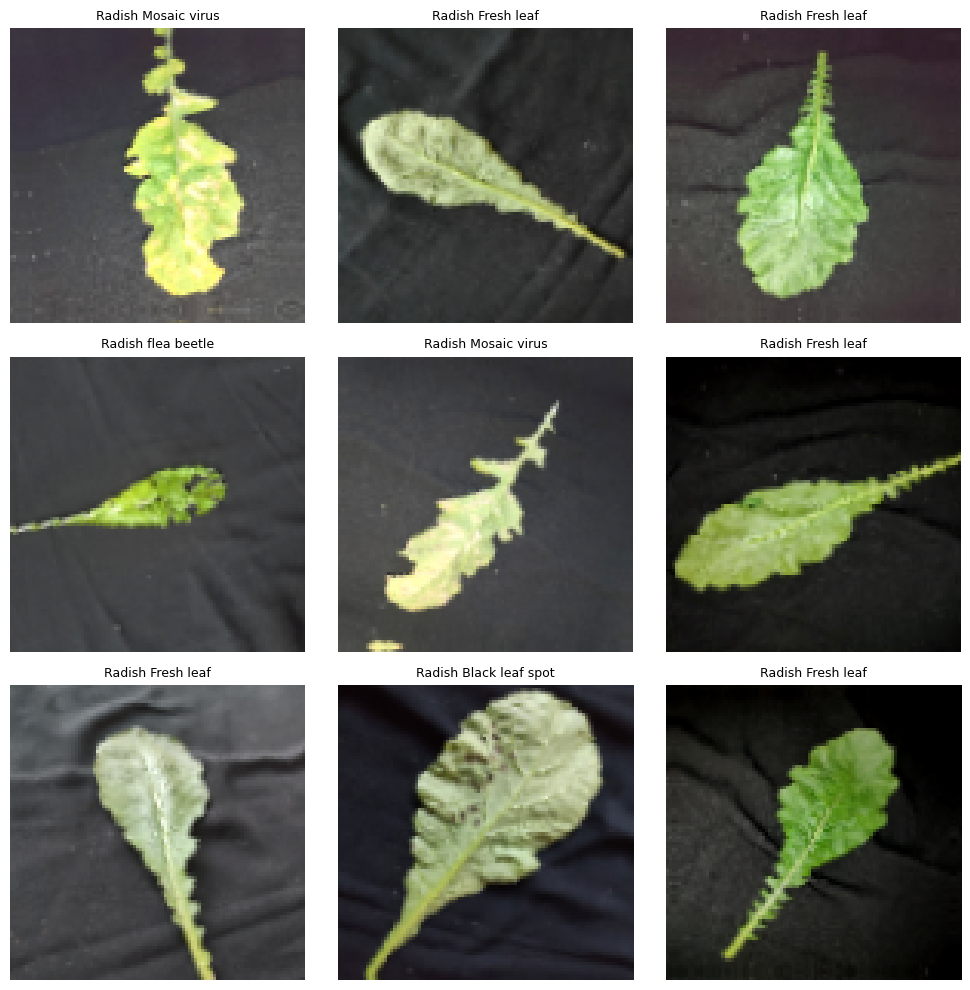

In [6]:
# Sanity check: visualize a batch of augmented training images
plt.figure(figsize=(10, 10))
for images, labels in train_ds_raw.take(1):
    aug_images = data_augmentation(images, training=True)
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(aug_images[i].numpy().astype("uint8"))
        plt.title(class_names[int(tf.argmax(labels[i]))], fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()


## 5. Model architecture — MobileNetV2 transfer learning

`alpha=0.75` is used here (not the very smallest 0.35 variant) to give the model enough
capacity to separate visually similar diseases first — you can shrink this back down later
during the ESP32-CAM quantization stage if the model doesn't fit in memory.


In [7]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
    alpha=0.75,
)
base_model.trainable = False   # freeze backbone for initial training

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()


5903360/5903360 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_0.75_96             │ (None, 3, 3, 1280)     │     1,382,064 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,464,373 (5.59 MB)

 Trainable params: 82,309 (321.52 KB)

 Non-trainable params: 1,382,064 (5.27 MB)

## 6. Training

In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)


Epoch 1/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 18s 215ms/step - accuracy: 0.6105 - loss: 1.0350 - val_accuracy: 0.7458 - val_loss: 0.5858 - learning_rate: 0.0010
Epoch 2/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 16s 148ms/step - accuracy: 0.8356 - loss: 0.4384 - val_accuracy: 0.8537 - val_loss: 0.3296 - learning_rate: 0.0010
Epoch 3/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 148ms/step - accuracy: 0.8851 - loss: 0.3083 - val_accuracy: 0.8825 - val_loss: 0.3160 - learning_rate: 0.0010
Epoch 4/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 151ms/step - accuracy: 0.9112 - loss: 0.2471 - val_accuracy: 0.8849 - val_loss: 0.3011 - learning_rate: 0.0010
Epoch 5/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 146ms/step - accuracy: 0.9311 - loss: 0.1868 - val_accuracy: 0.9305 - val_loss: 0.2147 - learning_rate: 0.0010
Epoch 6/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 150ms/step - accuracy: 0.9464 - loss: 0.1586 - val_accuracy: 0.9257 - val_loss: 0.2200 - learning_rate: 0.0010
Epoch 7/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 154ms/step - accuracy: 0.9500 - loss: 0.

In [9]:
# Optional gentle fine-tuning pass: unfreeze only the last ~10 layers at a very low
# learning rate. Skip this cell if validation accuracy is already good enough —
# unfreezing too much / too fast causes training instability (a loss spike).

base_model.trainable = True
fine_tune_at = len(base_model.layers) - 10
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-6),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

fine_tune_epochs = 5
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=fine_tune_epochs,
    callbacks=callbacks,
)


Epoch 1/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 16s 181ms/step - accuracy: 0.7555 - loss: 0.9236 - val_accuracy: 0.9568 - val_loss: 0.1574 - learning_rate: 1.0000e-06
Epoch 2/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 166ms/step - accuracy: 0.7631 - loss: 0.8653 - val_accuracy: 0.9520 - val_loss: 0.1651 - learning_rate: 1.0000e-06
Epoch 3/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 164ms/step - accuracy: 0.7800 - loss: 0.8337 - val_accuracy: 0.9448 - val_loss: 0.1773 - learning_rate: 5.0000e-07
Epoch 4/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 165ms/step - accuracy: 0.7739 - loss: 0.8038 - val_accuracy: 0.9448 - val_loss: 0.1901 - learning_rate: 5.0000e-07
Epoch 5/5
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 163ms/step - accuracy: 0.7698 - loss: 0.8570 - val_accuracy: 0.9353 - val_loss: 0.2050 - learning_rate: 2.5000e-07


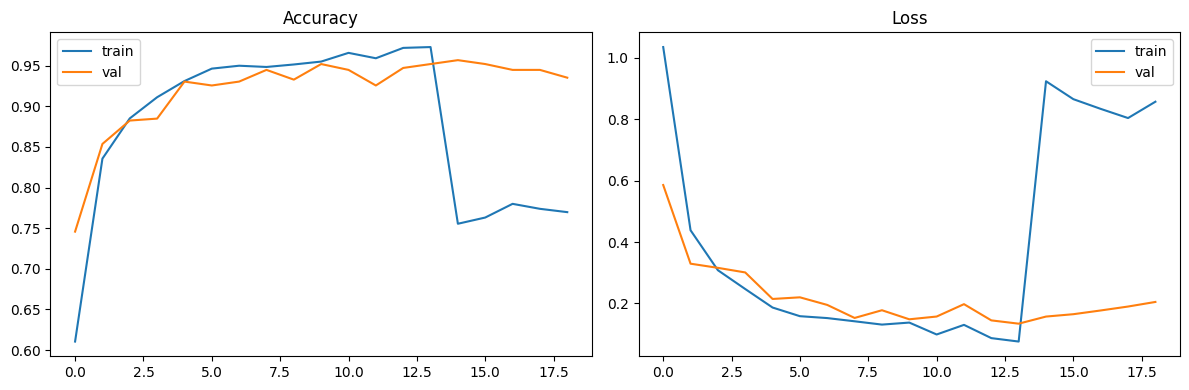

In [10]:
def plot_history(h1, h2=None):
    acc = h1.history["accuracy"]
    val_acc = h1.history["val_accuracy"]
    loss = h1.history["loss"]
    val_loss = h1.history["val_loss"]

    if h2 is not None:
        acc += h2.history["accuracy"]
        val_acc += h2.history["val_accuracy"]
        loss += h2.history["loss"]
        val_loss += h2.history["val_loss"]

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(acc, label="train")
    plt.plot(val_acc, label="val")
    plt.title("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(loss, label="train")
    plt.plot(val_loss, label="val")
    plt.title("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, history_fine if 'history_fine' in dir() else None)


## 7. Evaluation on the held-out test set

Reports accuracy, precision, recall, F1-score (per class and macro-averaged), and a
confusion matrix.


In [11]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

y_true = []
y_pred = []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=class_names))

precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
print(f"Macro Precision: {precision:.4f}  Macro Recall: {recall:.4f}  Macro F1: {f1:.4f}")


14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step - accuracy: 0.9482 - loss: 0.1546
Test accuracy: 0.9482
Test loss: 0.1546

Classification report:
                        precision    recall  f1-score   support

Radish Black leaf spot       0.91      0.91      0.91        80
  Radish Downey mildew       1.00      0.96      0.98        91
     Radish Fresh leaf       0.88      1.00      0.93        93
   Radish Mosaic virus       0.98      1.00      0.99        83
    Radish flea beetle       1.00      0.86      0.92        78

              accuracy                           0.95       425
             macro avg       0.95      0.95      0.95       425
          weighted avg       0.95      0.95      0.95       425

Macro Precision: 0.9533  Macro Recall: 0.9455  Macro F1: 0.9474


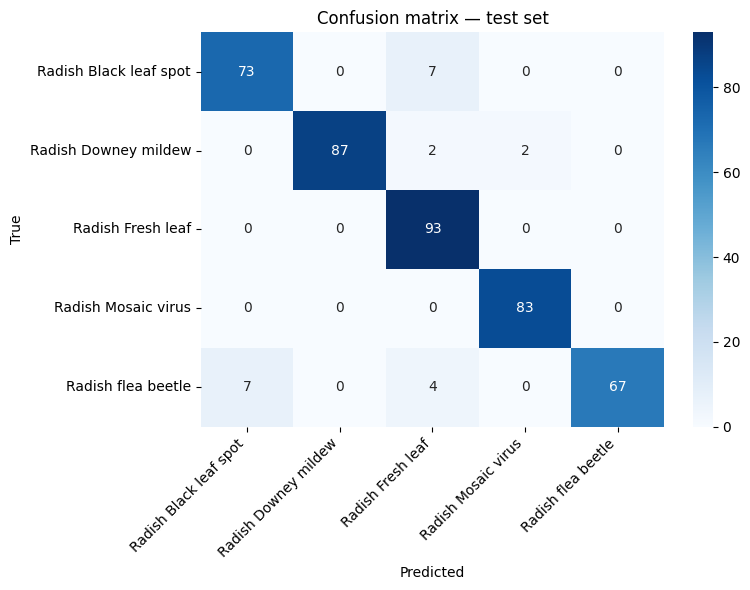

In [12]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix — test set")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 8. Save the trained model

Saves both a `.keras` file and a TensorFlow SavedModel folder (needed later for TFLite /
TFLite Micro conversion for ESP32-CAM deployment).


In [13]:
model.save(MODEL_SAVE_PATH)
model.export(MODEL_SAVEDMODEL_PATH)

with open(os.path.join(WORK_DIR, "class_names.txt"), "w") as f:
    for c in class_names:
        f.write(c + "\n")

print("Saved model to:", MODEL_SAVE_PATH)
print("Saved SavedModel export to:", MODEL_SAVEDMODEL_PATH)
print("Saved class names to:", os.path.join(WORK_DIR, "class_names.txt"))
print("\nNext step (separate stage): INT8 quantization + TFLite Micro conversion for ESP32-CAM.")


INFO:tensorflow:Assets written to: ./agrolens_radish_work\agrolens_radish_savedmodel\assets


INFO:tensorflow:Assets written to: ./agrolens_radish_work\agrolens_radish_savedmodel\assets


Saved artifact at './agrolens_radish_work\agrolens_radish_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name='keras_tensor_160')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2727963071824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963073360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963073168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963072592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963073936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963073552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963075472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963075280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963074896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727963076048: TensorSpec(shape=(), dtype=tf.resource, name=None)
 

## 9. Real-time inference — upload an image and get a live prediction

Run the cell below, click "Upload", pick any radish leaf photo, and the model's prediction
(disease name + confidence) displays immediately below it.


In [14]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image
import io

uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Upload leaf photo")
output = widgets.Output()

def predict_image(img: Image.Image):
    img_resized = img.convert("RGB").resize(IMG_SIZE)
    arr = np.array(img_resized).astype("float32") / 255.0
    arr = np.expand_dims(arr, axis=0)
    preds = model.predict(arr, verbose=0)[0]
    top_idx = int(np.argmax(preds))
    return class_names[top_idx], float(preds[top_idx]), preds

def on_upload_change(change):
    with output:
        clear_output()
        if not uploader.value:
            return
        uploaded_file = list(uploader.value.values())[0] if isinstance(uploader.value, dict) else uploader.value[0]
        content = uploaded_file["content"] if isinstance(uploaded_file, dict) else uploaded_file.content
        img = Image.open(io.BytesIO(content))

        predicted_class, confidence, all_preds = predict_image(img)

        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{predicted_class}\n{confidence*100:.1f}% confidence", fontsize=11)
        plt.show()

        print("Full class probabilities:")
        for cname, p in sorted(zip(class_names, all_preds), key=lambda x: -x[1]):
            print(f"  {cname:35s} {p*100:5.1f}%")

uploader.observe(on_upload_change, names="value")
display(uploader, output)


FileUpload(value=(), accept='image/*', description='Upload leaf photo')

Output()

### Notes

- If auto-detection in Section 2 failed, share the output of `os.listdir(DATASET_DIR)` and
  the loading code can be adjusted precisely.
- Radish disease classification has less established literature than PlantVillage/tomato —
  worth discussing explicitly in your paper if this is the dataset you commit to for the
  final project.
- The next stage (not in this notebook) converts `agrolens_radish_model.keras` into an
  INT8-quantized `.tflite` file sized for the ESP32-CAM.
